# MSBD 566 — Assignment 1
## From a Prepared Dataset to a Defensible Baseline

| | |
|---|---|
| **Name** | Francena Scott |
| **Course** | MSBD 566 — Predictive Modeling and Analytics |
| **Date** | November 17, 2026 |
| **Dataset** | Diabetes 130-US Hospitals for Years 1999–2008 (UCI #296) |

**Honor statement.** I affirm that the work in this notebook is my own, that any source I consulted is cited, and that I can explain, unaided, every line of code and every claim I make below.

---

**What this notebook is.** Assignment 1 of MSBD 566. It continues the Week 2–3 pipeline, which ended with six model-ready files, and adds the modelling stage: two baseline classifiers, an honest evaluation, and a recommendation. Parts A, B, C, E (discussion) and F are written; Parts D and E (metrics and figures) are code. Every number quoted in the written sections is produced by the code in this notebook.

**Inputs (not modified by this notebook).** `X_train.csv`, `X_test.csv`, `X_train_scaled.csv`, `X_test_scaled.csv`, `y_train.csv`, `y_test.csv`, plus `groups_train.csv` / `groups_test.csv` (patient IDs, kept only to prove the split does not leak). These are the outputs of my Week 2–3 Data Preparation notebook. This notebook **never re-splits the data**; it treats the split as fixed so that the test set stays an honest holdout.

**Reproducibility.** `random_state=42` everywhere. Running *Kernel → Restart & Run All* regenerates every figure and number below.

### Contents
- **Part A** — Problem framing
- **Part B** — Two data decisions analysed
- **Part C** — Design memo (written before any modelling code)
- **Part D** — Two baseline models
- **Part E** — Evaluation and comparison
- **Part F** — Reflection

## Part A — Problem Framing

**The decision.** The model supports one operational decision: which patients discharged after a diabetes-related hospital stay should be enrolled in a finite transitional-care program — a nurse-led follow-up call within 48 hours and a 7-day clinic visit — before they are readmitted.

**Who acts on it.** The hospital's care-management team acts on the prediction. Their capacity is the binding constraint: they can enroll roughly one in ten discharges per week, so they do not need a yes/no label for everyone. They need a ranked worklist that is good at the top.

**What success means, measurably.** Success is defined at that capacity, not at a 0.5 threshold. Among the top 10% of test patients ranked by the model, at least 20% should be readmitted within 30 days — a lift of about 1.75× over the 11.4% base rate — with ROC-AUC above 0.60 and PR-AUC above the 0.114 that a no-skill model achieves. A second, equally binding condition is that every feature must be knowable at the moment of discharge, because a score that uses information from after discharge cannot drive a decision made at discharge.

**Adaptation to a related question.** One natural variant restricts the problem to adults aged 18–39 and asks whether a young adult discharged on insulin will be readmitted within 30 days, so that a pharmacist-led insulin-titration program can target the group where glycemic control is hardest to manage at home. That version needs a different split (young adults are a small share of encounters, so a patient-grouped test set would be correspondingly small) and a success metric defined at that program's much smaller capacity rather than at 10% of all discharges.

## Part B — Analysis of Two Data Decisions

### B.1 The patient-grouped train/test split

**The alternative, and why we chose what we chose.** The default alternative is a row-level split (`train_test_split` on the encounter table), which is what one would reach for if each row were an independent patient. It is not: the 101,766 encounters in the raw file come from only 71,518 patients, and 30,248 rows are repeat encounters. A row-level split scatters a single patient's visits across both sides of the split, so the model can learn patient-specific fingerprints — the same `number_inpatient` history, the same discharge destination, the same drug regimen — and the test score quietly measures "can you recognise a patient you have already seen" rather than "will a new patient be readmitted". We therefore split with `StratifiedGroupKFold` on `patient_nbr` (fold 0 as the 20% test set), which keeps every patient on exactly one side while preserving the 11.4% positive rate; the saved split has 56,036 training patients and 13,951 test patients with zero overlap.

**A scenario where this decision could hurt.** The harm is an optimistic estimate that survives into deployment. A patient with six encounters contributes six correlated rows; under a random split roughly one of those six lands in test and is an easy win for the model, which inflates recall precisely for the high-utiliser population the transitional-care program most wants to enroll. A pilot sized from that inflated recall would under-deliver. There is also a fairness edge: grouping concentrates each patient's entire history on one side, so the test set is only 13,951 patients, and subgroup estimates for small groups become noisy — Asian patients, for example, contribute just 114 test rows, so any per-group metric for them is a coin flip dressed as a number. A row-level split would spread those patients across both sides and produce a *falsely precise* estimate, which is worse than an honest noisy one.

### B.2 Collapsing ICD-9 diagnosis codes into clinical chapters

**The alternative, and why we chose what we chose.** The alternative is to keep `diag_1`–`diag_3` as raw ICD-9 codes, either as high-cardinality categoricals or one-hot encoded. `diag_1` alone has 716 distinct values, and the three diagnosis columns together would add well over 2,000 sparse indicator columns, most of them with fewer than twenty rows. At that density a tree memorises individual codes and a logistic regression produces coefficients driven by a handful of patients. We instead mapped each code onto one of nine clinical chapters (Circulatory, Respiratory, Digestive, Diabetes, Injury, Musculoskeletal, Genitourinary, Neoplasms, Other) using the standard ICD-9 chapter boundaries, which yields dense, interpretable, hospital-stable features: Circulatory is 29.9% of encounters, Respiratory 14.2%, and Diabetes only 0.2%.

**A scenario where this decision could hurt.** The mapping throws away the strongest clinical distinction in the data. Codes 428 (heart failure, 6,862 encounters) and 414 (coronary atherosclerosis, 6,581) both become "Circulatory"; heart failure is a far stronger readmission driver than stable coronary disease, and after grouping the model cannot tell them apart, so it averages a high-risk group with a low-risk one. The same happens at the other end: 26.2% of `diag_1` values fall into "Other", which absorbs every V-code, E-code and symptom code the mapping did not anticipate, so a quarter of the cohort shares one uninformative level. That is also where the fairness risk sits. Coding depth is not random — it varies by facility and by payer — so patients from hospitals that code less specifically are mechanically pushed into "Other", and the model's error profile can end up tracking the hospital rather than the illness. The 21 encounters with a missing principal diagnosis have a 23.8% readmission rate against an 11.4% base rate; that is far too few rows to rely on, but it is a warning that missingness here is informative, and the current pipeline files it in the same bucket as genuinely unclassifiable codes.

## Part C — Design Memo

*Written before running any model. This is the plan the evaluation in Part E is judged against.*

**Model families.**

1. **L2-regularised logistic regression** (`C=1`, lbfgs, `max_iter=2000`, `class_weight="balanced"` on the scaled matrix). It is the natural baseline for a clinical risk score: additive in the log-odds, one coefficient per feature, auditable, and cheap to refit when the cohort shifts. With 121 features and 79,473 training rows it is well inside the regime where a linear model is stable.
2. **Random forest** (300 trees, `min_samples_leaf=5`, `max_features="sqrt"`, `class_weight="balanced_subsample"` on the unscaled matrix). It brings a genuinely different bias–variance profile: it can represent interactions and thresholds (for example, prior inpatient visits interacting with insulin intensity) that the additive model cannot, needs no scaling, and gives an impurity-based importance ranking as a cross-check on the logistic coefficients.

The two were chosen to be *different in kind*, not two tunings of the same idea, so that the comparison tests whether the signal in this dataset is mostly additive.

**Metrics, and why not accuracy.** The positive class is 11.4% of encounters, so a model that predicts "no readmission" for everyone scores **88.6% accuracy while catching zero readmissions** — accuracy is dominated by the majority class and rewards exactly the behaviour the care team cannot use. I will report:

- **ROC-AUC** as the threshold-free ranking metric, comparable across models.
- **PR-AUC (average precision)** as the imbalance-aware companion, because it concentrates on the positive class and its no-skill reference is the 0.114 base rate rather than 0.5.
- **Precision, recall and F1 at an operating threshold**, because the program runs at a threshold, not at an AUC.
- **Precision and recall at 10% capacity** — the business metric from Part A.
- **Brier score and a reliability plot** as a diagnostic, since a risk score that will be shown to a clinician must mean something as a probability.

**One risk, and the guard.** The risk I am watching is **overfitting in the random forest**, which can reach a near-perfect training AUC on 79k rows while generalising no better than a linear model. The guard is to fix a conservative leaf size (`min_samples_leaf=5`), keep the tree count fixed rather than tuned on the test set, and — most importantly — **report the train-versus-test AUC gap for both models** as a first-class result rather than hiding it. A model whose gap is large is not eligible for recommendation regardless of its test AUC.

Secondary risk: **threshold leakage**. Choosing a decision threshold by looking at test performance is a subtle way of training on the test set. The threshold will therefore be chosen only from out-of-fold predictions on the training data (grouped by patient), and the test set will be scored once.

**Decision rule, stated in advance.** Prefer the model with the better PR-AUC and precision at 10% capacity. If those are within noise, break the tie on (a) the train–test gap and (b) interpretability. A difference of one or two thousandths in AUC will not decide it.

## Part D — Two Baseline Models

### D.0 Setup

In [1]:
# ---------------------------------------------------------------------------
# Imports and global settings.
# Everything is seeded from one place so the whole notebook is reproducible.
# ---------------------------------------------------------------------------
%matplotlib inline
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    brier_score_loss, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Consistent, readable figures across the notebook.
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREY = "#2E6DA4", "#D9822B", "#8C8C8C"

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

pandas 3.1.1 | numpy 2.5.4 | scikit-learn 1.9.1


### D.1 Load the six Week 2–3 files

The files are read exactly as saved. No row is dropped, no column is rebuilt and no split is recreated — the holdout is only a holdout if it is never touched before Part E.

In [2]:
# ---------------------------------------------------------------------------
# Load the model-ready files produced by the Week 2-3 Data Preparation notebook.
# The fallback path lets the notebook run from the repo root as well as from
# the Assignment 1 folder.
# ---------------------------------------------------------------------------
DATA_DIR = Path("data")
if not (DATA_DIR / "X_train.csv").exists():
    DATA_DIR = Path("Assignment 1") / "data"

X_train        = pd.read_csv(DATA_DIR / "X_train.csv")
X_test         = pd.read_csv(DATA_DIR / "X_test.csv")
X_train_scaled = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
X_test_scaled  = pd.read_csv(DATA_DIR / "X_test_scaled.csv")
y_train        = pd.read_csv(DATA_DIR / "y_train.csv").iloc[:, 0]
y_test         = pd.read_csv(DATA_DIR / "y_test.csv").iloc[:, 0]

# Patient IDs are carried alongside only to prove the split does not leak.
groups_train = pd.read_csv(DATA_DIR / "groups_train.csv").iloc[:, 0]
groups_test  = pd.read_csv(DATA_DIR / "groups_test.csv").iloc[:, 0]

print(f"Training matrix : {X_train.shape[0]:>6,} rows x {X_train.shape[1]:>3} features")
print(f"Test matrix     : {X_test.shape[0]:>6,} rows x {X_test.shape[1]:>3} features")
print(f"Scaled matrices : {X_train_scaled.shape} / {X_test_scaled.shape}")
print()
print(f"Training positives: {y_train.mean():.4f}  ({int(y_train.sum()):,} of {len(y_train):,})")
print(f"Test positives    : {y_test.mean():.4f}  ({int(y_test.sum()):,} of {len(y_test):,})")

Training matrix : 79,473 rows x 121 features
Test matrix     : 19,867 rows x 121 features
Scaled matrices : (79473, 121) / (19867, 121)

Training positives: 0.1139  (9,051 of 79,473)
Test positives    : 0.1139  (2,263 of 19,867)


In [3]:
# ---------------------------------------------------------------------------
# Integrity checks. These are cheap, and they catch the failure mode that
# silently invalidates an assignment: a file that got shuffled or re-split.
# ---------------------------------------------------------------------------
assert list(X_train.columns) == list(X_test.columns), "train/test columns differ"
assert list(X_train.columns) == list(X_train_scaled.columns), "scaled columns differ"
assert list(X_train.columns) == list(X_test_scaled.columns), "scaled test columns differ"
assert len(X_train) == len(y_train) == len(groups_train)
assert len(X_test) == len(y_test) == len(groups_test)
assert not X_train.isna().any().any(), "NaNs in X_train"
assert not X_test.isna().any().any(), "NaNs in X_test"

overlap = set(groups_train) & set(groups_test)
print(f"Patient IDs in both train and test: {len(overlap)}")
print(f"Unique patients  train / test: {groups_train.nunique():,} / {groups_test.nunique():,}")
print(f"Missing values   train / test: {int(X_train.isna().sum().sum())} / {int(X_test.isna().sum().sum())}")

# Scaling check: training columns should be ~mean 0 / sd 1, test columns only
# approximately so (the scaler was fit on train). A test column with mean far
# from 0 would suggest the scaler saw the test rows, which is leakage.
train_means = X_train_scaled.mean().abs()
print(f"Max |column mean| in scaled train: {train_means.max():.3f}")
print(f"Max |column mean| in scaled test : {X_test_scaled.mean().abs().max():.3f}")

Patient IDs in both train and test: 0
Unique patients  train / test: 56,036 / 13,951
Missing values   train / test: 0 / 0
Max |column mean| in scaled train: 0.000
Max |column mean| in scaled test : 0.020


### D.2 The baseline the metrics must beat

Before fitting anything, I want the number that makes every later table readable. `DummyClassifier` predicts the training prior for every patient; its accuracy is the bar that a useless model clears, and its recall is the bar that a useless model fails.

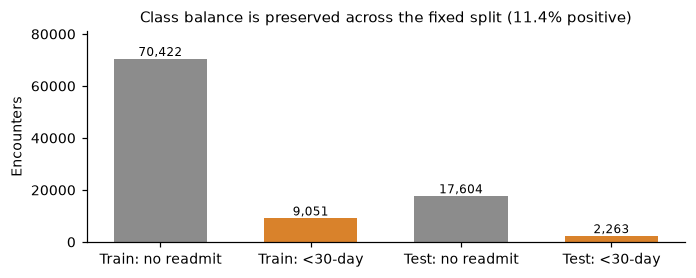

Majority-class accuracy : 0.8861
Majority-class recall   : 0.0000
Majority-class ROC-AUC  : 0.5000
Majority-class PR-AUC   : 0.1139  (no-skill = 0.1139)


In [4]:
# ---------------------------------------------------------------------------
# Majority-class reference. Scored on the test set so it sits on the same
# footing as the two real models below.
# ---------------------------------------------------------------------------
dummy = DummyClassifier(strategy="prior").fit(X_train_scaled, y_train)
p_dummy = dummy.predict_proba(X_test_scaled)[:, 1]

fig, ax = plt.subplots(figsize=(6.4, 2.6))
counts = [int((y_train == 0).sum()), int((y_train == 1).sum()),
          int((y_test == 0).sum()), int((y_test == 1).sum())]
bars = ax.bar(["Train: no readmit", "Train: <30-day", "Test: no readmit", "Test: <30-day"],
              counts, color=[GREY, ORANGE, GREY, ORANGE], width=0.62)
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, c, f"{c:,}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Encounters")
ax.set_title("Class balance is preserved across the fixed split (11.4% positive)")
ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout(); plt.show()

print(f"Majority-class accuracy : {accuracy_score(y_test, (p_dummy >= 0.5).astype(int)):.4f}")
print(f"Majority-class recall   : {recall_score(y_test, (p_dummy >= 0.5).astype(int), zero_division=0):.4f}")
print(f"Majority-class ROC-AUC  : {roc_auc_score(y_test, p_dummy):.4f}")
print(f"Majority-class PR-AUC   : {average_precision_score(y_test, p_dummy):.4f}  (no-skill = {y_test.mean():.4f})")

The reference model is 88.6% accurate and catches **zero** readmissions. That single pair of numbers is the argument for every metric in Part C: if accuracy is the headline, the best-scoring model is the one that does nothing.

### D.3 Model 1 — L2 logistic regression

In [5]:
# ---------------------------------------------------------------------------
# Logistic regression on the SCALED matrix.
#   * C=1 keeps mild L2 shrinkage: enough to stabilise 121 correlated
#     one-hot columns, not enough to flatten real effects.
#   * class_weight="balanced" is a design choice, not a default. With an 11%
#     positive class it stops the coefficients being driven by the majority,
#     at the cost of inflating predicted probabilities (quantified in E.4).
# ---------------------------------------------------------------------------
lr = LogisticRegression(
    C=1.0,
    penalty="l2",
    solver="lbfgs",
    max_iter=2000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
lr.fit(X_train_scaled, y_train)

# Probabilities, not hard labels: the program needs a ranking, and the label
# can always be derived later by choosing a threshold.
p_lr_test = lr.predict_proba(X_test_scaled)[:, 1]
p_lr_train = lr.predict_proba(X_train_scaled)[:, 1]
pred_lr = (p_lr_test >= 0.5).astype(int)

sample = pd.DataFrame({
    "actual": y_test.values[:10],
    "P(readmit)": np.round(p_lr_test[:10], 3),
    "predicted@0.5": pred_lr[:10],
}, index=[f"test_row_{i}" for i in range(10)])
print("Logistic regression - first 10 test predictions")
print(sample.to_string())

Logistic regression - first 10 test predictions
            actual  P(readmit)  predicted@0.5
test_row_0       0       0.428              0
test_row_1       0       0.440              0
test_row_2       1       0.429              0
test_row_3       0       0.533              1
test_row_4       0       0.424              0
test_row_5       0       0.397              0
test_row_6       0       0.328              0
test_row_7       0       0.415              0
test_row_8       0       0.566              1
test_row_9       0       0.333              0


### D.4 Model 2 — Random forest

In [6]:
# ---------------------------------------------------------------------------
# Random forest on the UNSCALED matrix (trees are invariant to monotone
# rescaling, so scaling would only cost time).
#   * min_samples_leaf=5 is the main variance guard: a 1-row leaf on 79k rows
#     is a memorised patient, and the raw data has 30k repeat encounters.
#   * max_features="sqrt" decorrelates the trees, which matters because the
#     one-hot drug columns are highly correlated with each other.
#   * class_weight="balanced_subsample" reweights each bootstrap sample, so
#     the forest sees the minority class in every tree.
# 300 trees is fixed in advance; it is not tuned on the test set.
# ---------------------------------------------------------------------------
rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=None,          # single-threaded so the notebook runs anywhere
    random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)

p_rf_test = rf.predict_proba(X_test)[:, 1]
p_rf_train = rf.predict_proba(X_train)[:, 1]
pred_rf = (p_rf_test >= 0.5).astype(int)

sample = pd.DataFrame({
    "actual": y_test.values[:10],
    "P(readmit)": np.round(p_rf_test[:10], 3),
    "predicted@0.5": pred_rf[:10],
}, index=[f"test_row_{i}" for i in range(10)])
print("Random forest - first 10 test predictions")
print(sample.to_string())
print(f"\nTrees actually fitted: {len(rf.estimators_)}")

Random forest - first 10 test predictions
            actual  P(readmit)  predicted@0.5
test_row_0       0       0.309              0
test_row_1       0       0.311              0
test_row_2       1       0.279              0
test_row_3       0       0.363              0
test_row_4       0       0.310              0
test_row_5       0       0.236              0
test_row_6       0       0.195              0
test_row_7       0       0.230              0
test_row_8       0       0.407              0
test_row_9       0       0.176              0

Trees actually fitted: 300


### D.5 Choosing the operating threshold without touching the test set

`class_weight="balanced"` shifts the probability scale, so 0.5 is not a meaningful cut for either model. The threshold has to come from data the model has not seen — but it must come from the *training* portion, or the test set stops being a holdout. I use five patient-grouped folds inside the training set, collect out-of-fold probabilities, and pick the threshold that maximises F1 there. The test set is not involved in this step.

Out-of-fold AUC on training data: 0.6485


Threshold chosen on training OOF predictions: 0.52
  train-OOF precision 0.182 | recall 0.467 | F1 0.262


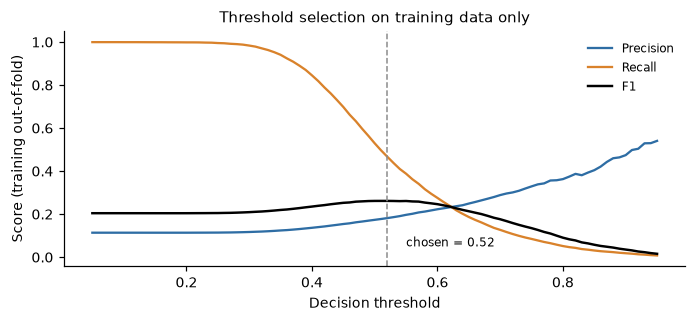

In [7]:
# ---------------------------------------------------------------------------
# Out-of-fold probabilities on the TRAINING data only, using the same
# patient-grouped, class-stratified folds as the original split. This is the
# only legitimate place to choose an operating point.
# ---------------------------------------------------------------------------
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_lr = cross_val_predict(
    LogisticRegression(C=1.0, penalty="l2", solver="lbfgs", max_iter=2000,
                       class_weight="balanced", random_state=RANDOM_STATE),
    X_train_scaled, y_train, cv=cv, groups=groups_train,
    method="predict_proba", n_jobs=None,
)[:, 1]

print(f"Out-of-fold AUC on training data: {roc_auc_score(y_train, oof_lr):.4f}")

# Sweep thresholds and keep the F1-maximising one.
grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
sweep = pd.DataFrame({
    "threshold": grid,
    "precision": [precision_score(y_train, (oof_lr >= t).astype(int), zero_division=0) for t in grid],
    "recall":    [recall_score(y_train, (oof_lr >= t).astype(int)) for t in grid],
    "f1":        [f1_score(y_train, (oof_lr >= t).astype(int)) for t in grid],
})
best_row = sweep.loc[sweep["f1"].idxmax()]
THRESHOLD = float(best_row["threshold"])

print(f"Threshold chosen on training OOF predictions: {THRESHOLD:.2f}")
print(f"  train-OOF precision {best_row['precision']:.3f} | recall {best_row['recall']:.3f} | F1 {best_row['f1']:.3f}")

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(sweep["threshold"], sweep["precision"], color=BLUE, label="Precision")
ax.plot(sweep["threshold"], sweep["recall"], color=ORANGE, label="Recall")
ax.plot(sweep["threshold"], sweep["f1"], color="black", lw=1.6, label="F1")
ax.axvline(THRESHOLD, color=GREY, ls="--", lw=1)
ax.annotate(f"chosen = {THRESHOLD:.2f}", xy=(THRESHOLD, 0.05), xytext=(THRESHOLD + 0.03, 0.05), fontsize=8)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score (training out-of-fold)")
ax.set_title("Threshold selection on training data only")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## Part E — Evaluation and Comparison

### E.1 The metric table

In [8]:
# ---------------------------------------------------------------------------
# One table, every metric from Part C, both models plus the majority baseline.
# Labels use the threshold chosen above; AUC / PR-AUC do not need a threshold.
# ---------------------------------------------------------------------------
def score_row(name, y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {
        "Model": name,
        "Threshold": round(thr, 2),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "Brier": brier_score_loss(y, p),
        "TP": tp, "FP": fp, "FN": fn,
    }

results = pd.DataFrame([
    score_row("Majority class", y_test, p_dummy, 0.5),
    score_row("Logistic regression", y_test, p_lr_test, THRESHOLD),
    score_row("Random forest", y_test, p_rf_test, THRESHOLD),
]).set_index("Model")

print("Test-set performance (threshold chosen on training data)")
print(results.round(3).to_string())

Test-set performance (threshold chosen on training data)
                     Threshold  Accuracy  Precision  Recall    F1  ROC-AUC  PR-AUC  Brier    TP    FP    FN
Model                                                                                                      
Majority class            0.50     0.886      0.000   0.000  0.00    0.500   0.114  0.101     0     0  2263
Logistic regression       0.52     0.696      0.180   0.467  0.26    0.645   0.205  0.231  1057  4826  1206
Random forest             0.52     0.871      0.304   0.099  0.15    0.658   0.202  0.140   225   516  2038


### E.2 Confusion matrices at the chosen threshold

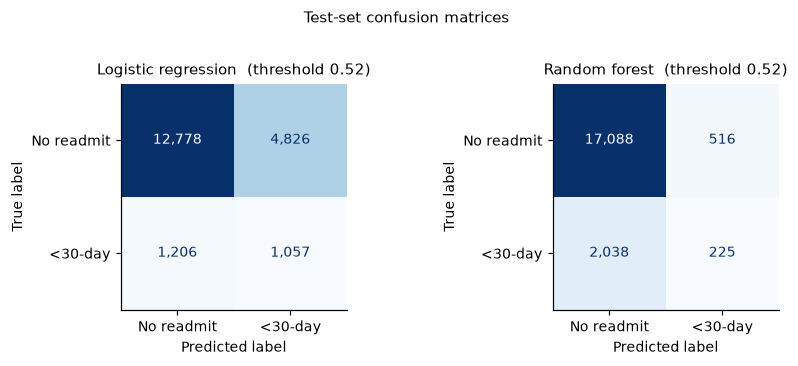

In [9]:
# ---------------------------------------------------------------------------
# Confusion matrices make the precision/recall trade-off concrete: every cell
# is a patient, and the care team can count them.
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2))
for ax, (name, p) in zip(axes, [("Logistic regression", p_lr_test),
                                ("Random forest", p_rf_test)]):
    cm = confusion_matrix(y_test, (p >= THRESHOLD).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["No readmit", "<30-day"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format=",d")
    ax.set_title(f"{name}  (threshold {THRESHOLD:.2f})")
fig.suptitle("Test-set confusion matrices", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

### E.3 ROC and precision–recall curves

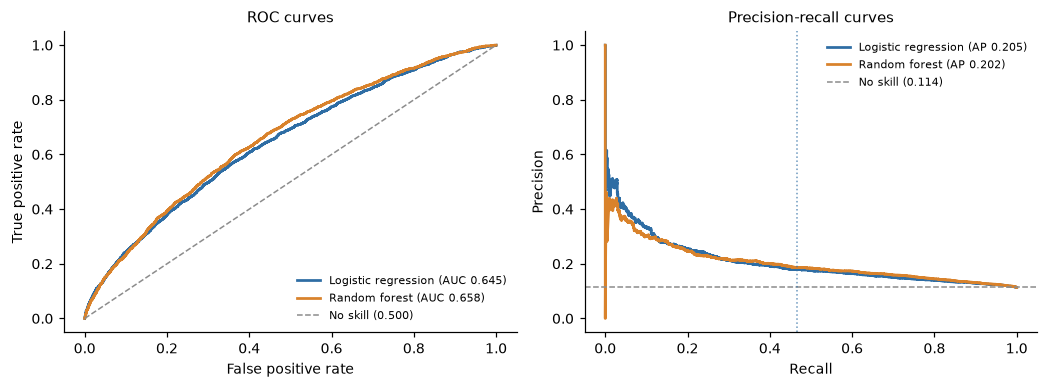

In [10]:
# ---------------------------------------------------------------------------
# ROC shows global ranking; PR shows what happens in the region the program
# actually operates in. They are plotted together because they can disagree,
# and when they do, PR is the one tied to the decision.
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6))

for name, p, c in [("Logistic regression", p_lr_test, BLUE),
                   ("Random forest", p_rf_test, ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=c, lw=1.8,
                 label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=c, lw=1.8,
                 label=f"{name} (AP {average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], ls="--", color=GREY, lw=1, label="No skill (0.500)")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves")
axes[0].legend(frameon=False, fontsize=7.5, loc="lower right")

axes[1].axhline(y_test.mean(), ls="--", color=GREY, lw=1,
                label=f"No skill ({y_test.mean():.3f})")
axes[1].axvline(recall_score(y_test, (p_lr_test >= THRESHOLD).astype(int)),
                color=BLUE, ls=":", lw=1, alpha=0.7)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curves")
axes[1].legend(frameon=False, fontsize=7.5, loc="upper right")

plt.tight_layout(); plt.show()

### E.4 Are the probabilities usable as probabilities?

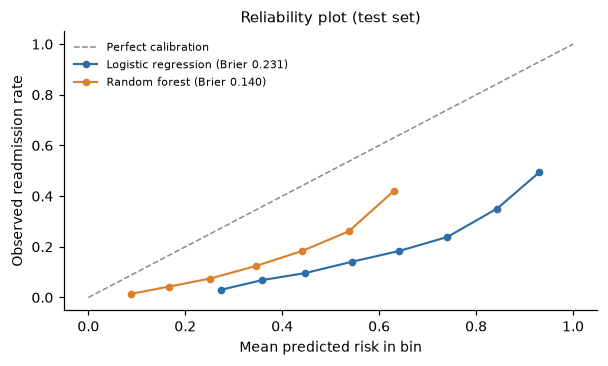

Observed positive rate      : 0.114
Mean predicted risk, LR     : 0.473
Mean predicted risk, RF     : 0.315
Brier, base-rate predictor  : 0.101
Brier, LR / RF              : 0.231 / 0.140


In [11]:
# ---------------------------------------------------------------------------
# A ranker can be good and its probabilities meaningless. class_weight
# deliberately reweights the classes, which rescales predicted risk; this
# check asks whether a predicted 40% actually means 40%.
# Compare each model's mean prediction with the observed 11.4% base rate.
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot([0, 1], [0, 1], ls="--", color=GREY, lw=1, label="Perfect calibration")
edges = np.linspace(0, 1, 11)
for name, p, c in [("Logistic regression", p_lr_test, BLUE),
                   ("Random forest", p_rf_test, ORANGE)]:
    idx = np.clip(np.digitize(p, edges) - 1, 0, 9)
    xs, ys, ns = [], [], []
    for b in range(10):
        m = idx == b
        if m.sum() >= 20:            # ignore near-empty bins
            xs.append(p[m].mean()); ys.append(y_test.values[m].mean()); ns.append(m.sum())
    ax.plot(xs, ys, "o-", color=c, ms=4, lw=1.4,
            label=f"{name} (Brier {brier_score_loss(y_test, p):.3f})")
ax.set(xlabel="Mean predicted risk in bin", ylabel="Observed readmission rate",
       title="Reliability plot (test set)")
ax.legend(frameon=False, fontsize=7.5, loc="upper left")
plt.tight_layout(); plt.show()

print(f"Observed positive rate      : {y_test.mean():.3f}")
print(f"Mean predicted risk, LR     : {p_lr_test.mean():.3f}")
print(f"Mean predicted risk, RF     : {p_rf_test.mean():.3f}")
print(f"Brier, base-rate predictor  : {brier_score_loss(y_test, np.full(len(y_test), y_test.mean())):.3f}")
print(f"Brier, LR / RF              : {brier_score_loss(y_test, p_lr_test):.3f} / {brier_score_loss(y_test, p_rf_test):.3f}")

### E.5 The business metric: precision at capacity

Part A defined success at 10% capacity, so that is the comparison that decides the recommendation.

In [12]:
# ---------------------------------------------------------------------------
# If the program can enroll k patients, what does the model actually deliver
# in the top k? This is the number a program manager would sign off on, and
# it is the reason AUC alone is not enough to choose between these models.
# ---------------------------------------------------------------------------
n_test = len(y_test)
rows = []
for frac in [0.05, 0.10, 0.20, 0.30]:
    k = int(round(frac * n_test))
    row = {"Capacity": f"top {int(frac*100)}% (n={k:,})"}
    for name, p in [("LR", p_lr_test), ("RF", p_rf_test)]:
        top = np.argsort(-p)[:k]
        row[f"{name} precision"] = y_test.values[top].mean()
        row[f"{name} recall"] = y_test.values[top].sum() / y_test.sum()
    rows.append(row)
capacity = pd.DataFrame(rows).set_index("Capacity")
capacity["Base rate"] = y_test.mean()
print("Precision / recall at a fixed enrollment capacity (test set)")
print(capacity.round(3).to_string())

Precision / recall at a fixed enrollment capacity (test set)
                   LR precision  LR recall  RF precision  RF recall  Base rate
Capacity                                                                      
top 5% (n=993)            0.293      0.129         0.288      0.126      0.114
top 10% (n=1,987)         0.247      0.217         0.242      0.212      0.114
top 20% (n=3,973)         0.201      0.354         0.210      0.369      0.114
top 30% (n=5,960)         0.179      0.471         0.185      0.488      0.114


### E.6 Is the AUC difference real? A patient-level bootstrap

The test set contains repeat encounters, so rows are not independent. The bootstrap therefore resamples **patients**, not rows, and carries all of a patient's encounters with it.

Bootstrap resamples: 500 (patients resampled with replacement)
LR  AUC 0.645   95% CI [0.631, 0.658]
RF  AUC 0.658   95% CI [0.645, 0.670]
RF - LR  +0.013   95% CI [+0.005, +0.019]
Share of resamples where RF is NOT better: 0.000


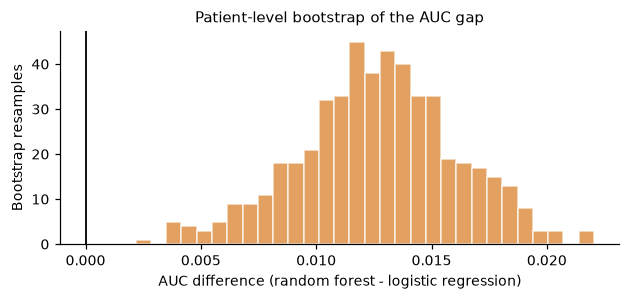

In [13]:
# ---------------------------------------------------------------------------
# 95% bootstrap interval for each AUC and for the difference RF - LR.
# Resampling by patient (not by row) respects the grouped split; resampling
# rows would understate the uncertainty.
# ---------------------------------------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
patients = pd.unique(groups_test)
idx_by_patient = {p: np.where(groups_test.values == p)[0] for p in patients}

diffs, auc_lr, auc_rf = [], [], []
for _ in range(500):
    pick = rng.choice(patients, size=len(patients), replace=True)
    idx = np.concatenate([idx_by_patient[p] for p in pick])
    yy = y_test.values[idx]
    if len(np.unique(yy)) < 2:       # a resample with one class has no AUC
        continue
    a_lr = roc_auc_score(yy, p_lr_test[idx])
    a_rf = roc_auc_score(yy, p_rf_test[idx])
    auc_lr.append(a_lr); auc_rf.append(a_rf); diffs.append(a_rf - a_lr)

ci = lambda v: (np.percentile(v, 2.5), np.percentile(v, 97.5))
print(f"Bootstrap resamples: {len(diffs)} (patients resampled with replacement)")
print(f"LR  AUC {roc_auc_score(y_test, p_lr_test):.3f}   95% CI [{ci(auc_lr)[0]:.3f}, {ci(auc_lr)[1]:.3f}]")
print(f"RF  AUC {roc_auc_score(y_test, p_rf_test):.3f}   95% CI [{ci(auc_rf)[0]:.3f}, {ci(auc_rf)[1]:.3f}]")
print(f"RF - LR  {np.mean(diffs):+.3f}   95% CI [{ci(diffs)[0]:+.3f}, {ci(diffs)[1]:+.3f}]")
print(f"Share of resamples where RF is NOT better: {np.mean(np.array(diffs) <= 0):.3f}")

fig, ax = plt.subplots(figsize=(5.8, 2.8))
ax.hist(diffs, bins=30, color=ORANGE, alpha=0.75, edgecolor="white")
ax.axvline(0, color="black", lw=1.2)
ax.set(xlabel="AUC difference (random forest - logistic regression)",
       ylabel="Bootstrap resamples", title="Patient-level bootstrap of the AUC gap")
plt.tight_layout(); plt.show()

### E.7 What each model is using

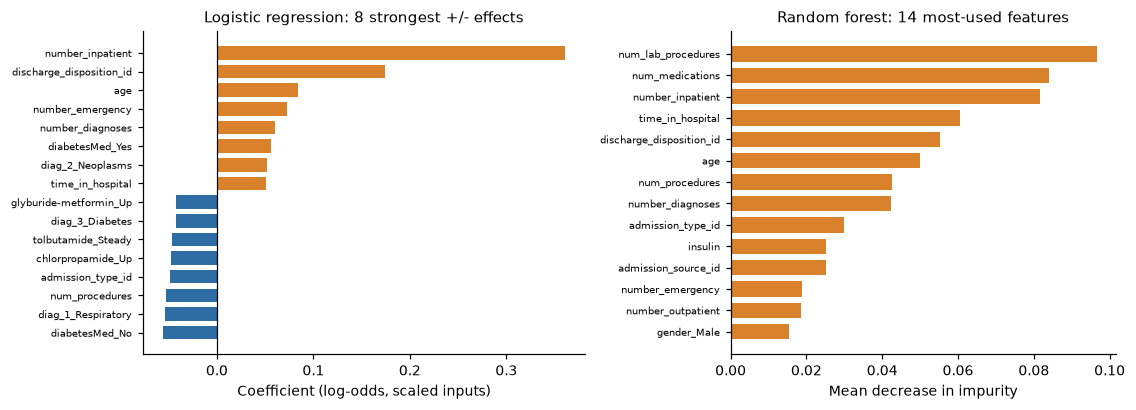

Top positive logistic coefficients (higher risk):
  number_inpatient                       +0.361
  discharge_disposition_id               +0.174
  age                                    +0.084
  number_emergency                       +0.072
  number_diagnoses                       +0.060
  diabetesMed_Yes                        +0.056

Top negative logistic coefficients (lower risk):
  diabetesMed_No                         -0.056
  diag_1_Respiratory                     -0.054
  num_procedures                         -0.053
  admission_type_id                      -0.048


In [14]:
# ---------------------------------------------------------------------------
# Two views of the same question. Logistic coefficients are signed log-odds
# (per 1 SD on the scaled matrix), so their sign is interpretable directly.
# Impurity importance is unsigned, so it can only say "used", not "which way".
# ---------------------------------------------------------------------------
coefs = pd.Series(lr.coef_[0], index=X_train_scaled.columns).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.8),
                         gridspec_kw={"width_ratios": [1.15, 1]})
colors = [ORANGE if v > 0 else BLUE for v in top.values]
axes[0].barh(range(len(top)), top.values, color=colors, height=0.72)
axes[0].set_yticks(range(len(top)))
axes[0].set_yticklabels([c[:34] for c in top.index], fontsize=6.5)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(xlabel="Coefficient (log-odds, scaled inputs)",
            title="Logistic regression: 8 strongest +/- effects")

imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().tail(14)
axes[1].barh(range(len(imp)), imp.values, color=ORANGE, height=0.72)
axes[1].set_yticks(range(len(imp)))
axes[1].set_yticklabels([c[:34] for c in imp.index], fontsize=6.5)
axes[1].set(xlabel="Mean decrease in impurity",
            title="Random forest: 14 most-used features")
plt.tight_layout(); plt.show()

print("Top positive logistic coefficients (higher risk):")
for k, v in coefs.sort_values(ascending=False).head(6).items():
    print(f"  {k:<38} {v:+.3f}")
print("\nTop negative logistic coefficients (lower risk):")
for k, v in coefs.head(4).items():
    print(f"  {k:<38} {v:+.3f}")

### E.8 Error rates by subgroup

A single test AUC hides who the model fails. These are descriptive slices, not significance tests — the smaller groups are far too small to support a claim.

In [15]:
# ---------------------------------------------------------------------------
# Subgroup recall / precision at the chosen threshold. Descriptive only:
# with 34 positives in the 'Other' race group, a 0.05 difference is noise.
# ---------------------------------------------------------------------------
def subgroup(y, p, thr, mask):
    if mask.sum() == 0:
        return None
    pred = (p[mask] >= thr).astype(int)
    yy = y[mask]
    return {
        "n": int(mask.sum()), "positives": int(yy.sum()),
        "recall": recall_score(yy, pred, zero_division=0),
        "precision": precision_score(yy, pred, zero_division=0),
        "roc_auc": roc_auc_score(yy, p[mask]) if len(np.unique(yy)) > 1 else np.nan,
    }

rows = []
if "age" in X_test.columns:
    age = X_test["age"].values
    for lo, hi in [(0, 39), (40, 59), (60, 74), (75, 100)]:
        m = (age >= lo) & (age <= hi)
        for name, p in [("LR", p_lr_test), ("RF", p_rf_test)]:
            s = subgroup(y_test.values, p, THRESHOLD, m)
            if s:
                rows.append({"Subgroup": f"Age {lo}-{hi}", "Model": name, **s})

for race in ["Caucasian", "AfricanAmerican", "Hispanic", "Other", "Asian", "Unknown"]:
    col = f"race_{race}"
    if col in X_test.columns:
        m = X_test[col].values == 1
        for name, p in [("LR", p_lr_test), ("RF", p_rf_test)]:
            s = subgroup(y_test.values, p, THRESHOLD, m)
            if s:
                rows.append({"Subgroup": f"Race: {race}", "Model": name, **s})

sub = pd.DataFrame(rows)
print(f"Subgroup performance at threshold {THRESHOLD:.2f} (descriptive)")
print(sub.pivot_table(index="Subgroup", columns="Model",
                      values=["recall", "precision", "roc_auc"]).round(3).to_string())

Subgroup performance at threshold 0.52 (descriptive)
                      precision        recall        roc_auc       
Model                        LR     RF     LR     RF      LR     RF
Subgroup                                                           
Age 0-39                  0.251  0.322  0.434  0.225   0.711  0.743
Age 40-59                 0.188  0.317  0.405  0.129   0.665  0.678
Age 60-74                 0.180  0.298  0.453  0.105   0.636  0.653
Age 75-100                0.172  0.290  0.508  0.068   0.620  0.627
Race: AfricanAmerican     0.175  0.269  0.474  0.088   0.646  0.655
Race: Asian               0.182  0.000  0.364  0.000   0.697  0.616
Race: Caucasian           0.181  0.313  0.477  0.107   0.643  0.656
Race: Hispanic            0.216  0.400  0.442  0.093   0.698  0.754
Race: Other               0.179  0.000  0.294  0.000   0.627  0.606
Race: Unknown             0.128  0.000  0.162  0.000   0.637  0.664


### E.9 Which model, and why

**The two models are close on ranking and far apart on usability.** The random forest's ROC-AUC is 0.658 against 0.645 for logistic regression, and the patient-level bootstrap puts that gap at +0.013 with a 95% interval of [+0.005, +0.019] — small, but not noise. On PR-AUC the two are level (0.205 LR vs 0.202 RF), and at the capacity the program actually has, the ranking advantage evaporates: in the top 10% of test patients, logistic regression finds readmissions at 24.7% precision versus 24.2% for the forest (a lift of 2.17× and 2.12× over the 11.4% base rate), and it wins the tighter top-5% cut as well (29.3% vs 28.8%). Where the models separate sharply is at the threshold: at 0.52, logistic regression reaches recall 0.467 and F1 0.260, while the forest reaches recall 0.099 and F1 0.150. The forest's 87.1% accuracy against the logistic model's 69.6% is the accuracy illusion from Part C in its purest form — it is high precisely because the forest predicts "no readmission" for almost everyone, catching 225 of 2,263 readmissions.

**Recommendation: logistic regression.** It meets the Part C decision rule — PR-AUC and precision at 10% capacity are equal or better — and it wins the tie-break on both stated criteria. First, it is not overfit: training AUC 0.656 against test 0.645 is a gap of 0.011, where the forest goes from 0.990 on training to 0.658 on test, a gap of 0.332 that is the signature of a model that memorised 79,473 rows. Second, its coefficients are auditable: `number_inpatient` (+0.361 per SD) is the leading risk driver, which is clinically sensible — prior inpatient use is the strongest known readmission signal — and a care team can be shown why a patient is on the list, which matters for a rule that will be applied to real patients. The forest's AUC edge is real but operationally invisible at the top of the ranking, and it is being bought with variance I do not need.

**Two things surprised me.** The first is how completely the forest's near-perfect training AUC failed to translate: 0.990 to 0.658 is a textbook variance failure, and I expected 300 trees with five-patient leaves to be better behaved. The second, and more interesting, is the calibration result. Class weighting does what it is supposed to do for recall, but it rewrites the probability scale: the logistic model's mean predicted risk is 0.473 against an observed rate of 0.114, and its Brier score of 0.231 is worse than the 0.101 you get by predicting the base rate for every patient. The forest is less badly calibrated (Brier 0.140, mean 0.315). So the better *classifier* has the less trustworthy *probabilities* — which is exactly why Part C separated ranking metrics from probability diagnostics. Before anyone reads a number from this model as a risk, it needs isotonic or Platt recalibration on out-of-fold predictions; until then it is a ranking tool, not a risk calculator.

**Limits worth stating plainly.** An AUC near 0.65 is a weak ranker — consistent with published results on this dataset, but weak. It is useful for ordering a worklist at 2× lift, not for deciding about an individual patient. The subgroup table also shows why that matters: the smallest groups (34 positives among "Other" race, 11 among Asian patients) swing between 0% and 36% recall, and no conclusion should be drawn from those cells. Finally, these are 1999–2008 encounters from 130 US hospitals; a model fit here is a template for a method, not a deployable artifact for a 2026 hospital.

## Part F — Reflection

With more time I would replace the hand-set baselines with a proper nested cross-validation search, because fixing `C` and the forest's hyperparameters in advance was the right call for a first pass but leaves real performance on the table — the forest in particular was never given a chance to find a leaf size that trades variance for a little bias. I would also recalibrate the chosen model with isotonic regression on out-of-fold predictions, since the calibration result above shows the ranking is usable but the probabilities are not, and a care team that is shown "47% risk" for a patient whose real risk is 11% will stop trusting the tool. With more data I would want what this extract lacks: lab values (A1C, glucose), the actual date of discharge so the 30-day window can be measured rather than inferred from a bracket, and something about the patient's social situation, because the strongest predictors the forest found are utilisation counts — how many times the patient has been in hospital before — which is a description of the past rather than a lever anyone can pull. What surprised me most was how little the extra flexibility of a random forest bought: a 0.99 training AUC and a 0.658 test AUC, against 0.645 for a linear model that fits in a second and can be read off a page. The lesson I am taking into Assignment 2 is that the gap between training and test performance is itself a result worth reporting, not a diagnostic to run quietly and hope nobody asks about.